# fMRI Preprocessing Methods
### Real multimodal inputs, core algorithms, and before/after evidence

**Presentation dataset:** OpenNeuro **ds000114**, participant **sub-01**, test and retest acquisitions.  
**Purpose:** explain the preprocessing operations already demonstrated in our reference library.  
**Scope:** real-data examples and mathematical verification; a complete production preprocessing benchmark remains pending.

> All figures and results are embedded in this notebook. Existing outputs can be presented immediately. Rerunning requires the reference repository, its environment, and the checksum-verified input data.

In [1]:
from pathlib import Path
import os, sys, json, hashlib

ROOT = (Path(os.environ["FMRI_REFERENCE_ROOT"]).resolve()
        if "FMRI_REFERENCE_ROOT" in os.environ
        else next((p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / "fmri_reference/core.py").is_file()), None))
if ROOT is None:
    raise FileNotFoundError("Run inside the reference repository or set FMRI_REFERENCE_ROOT.")
REPORT = ROOT / "reports/presentation"
FIGURES = REPORT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
sys.path[:0] = [str(ROOT), str(REPORT)]

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from nibabel.processing import resample_from_to
from nilearn.image import smooth_img
from nilearn import signal as nilearn_signal
from fmri_reference.core import (load_sample, canonical, resample_volume,
    temporal_resample, crop_or_pad, drift_basis, regress, scale, dvars, tsnr)
from fmri_reference.registration import rigid
import report_visuals as viz

viz.setup_style()
viz.install_notebook_style()
viz.html('<div class="hero"><div class="eyebrow">METHODS REPORT · REAL DATA</div>'
         '<h1>From heterogeneous scans<br>to explicit, auditable model inputs</h1>'
         '<div>Spatial geometry · Temporal sampling · Signal cleaning · Signal scale</div></div>')

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


## 01 · Our data structure

The input is a small, real **multimodal BIDS-organized subset**. The same participant was scanned twice. Each BOLD run contains a three-dimensional volume at every time point, so its array is **X × Y × Z × T**. Structural T1w and diffusion MRI provide separate modalities.

The BOLD sidecar and event file are stored at the dataset root and inherited by the corresponding runs. **Array values alone are insufficient:** the NIfTI affine locates voxels in physical space; the JSON sidecar defines timing; the event table records task onset and duration.

In [2]:
manifest = json.loads((ROOT / "provenance/data_manifest.json").read_text())
for entry in manifest:
    path = ROOT / "data/ds000114" / entry["path"]
    if not path.is_file():
        raise FileNotFoundError(f"Missing frozen input: {path}. Run scripts/download_data.py first.")
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(2**20), b""):
            digest.update(block)
    if path.stat().st_size != entry["bytes"] or digest.hexdigest() != entry["sha256"]:
        raise ValueError(f"Input checksum mismatch: {entry['path']}")

sample = load_sample(ROOT, session="test", max_features=128)
retest = load_sample(ROOT, session="retest", max_features=128)
x = sample["signals"]                 # time x features; 128 fixed example voxels
tr = sample["timing"]["tr_seconds"]
t = np.arange(len(x)) * tr
mean_bold = sample["mean_image"]
mask = sample["mask"]                 # estimated EPI mask; not anatomical coverage
DATA = ROOT / "data/ds000114"
t1 = nib.load(DATA / "sub-01/ses-test/anat/sub-01_ses-test_T1w.nii.gz")
dwi = nib.load(DATA / "sub-01/ses-test/dwi/sub-01_ses-test_dwi.nii.gz")
bvals = np.loadtxt(DATA / "dwi.bval")
assert bvals[0] == 0, "The multimodal figure requires a verified b=0 volume."
b0 = nib.Nifti1Image(np.asarray(dwi.dataobj[..., 0], dtype=np.float32), dwi.affine)
events = pd.read_csv(DATA / "task-fingerfootlips_events.tsv", sep="\t")
summary = json.loads((ROOT / "reports/validation_summary.json").read_text())

viz.cards([
    ("Participant / sessions", "1 / 2", "sub-01 · test / retest"),
    ("BOLD volumes per run", str(len(x)), "64 x 64 x 30 spatial grid"),
    ("Repetition time", f"{tr:.1f} s", f"Sampling rate: {1/tr:.2f} Hz"),
    ("Nominal run duration", f"{len(x)*tr:.0f} s", f"Sample span: {t[-1]:.1f} s")
])
viz.html('<pre>ds000114/\n'
    '├── dataset_description.json          # dataset identity and CC0 license\n'
    '├── participants.tsv                  # participant metadata\n'
    '├── task-fingerfootlips_bold.json      # inherited TR and SliceTiming\n'
    '├── task-fingerfootlips_events.tsv     # onset, duration, trial type\n'
    '├── dwi.bval / dwi.bvec                # diffusion encoding\n'
    '└── sub-01/\n'
    '    ├── ses-test/\n'
    '    │   ├── anat/..._T1w.nii.gz\n'
    '    │   ├── func/..._task-fingerfootlips_bold.nii.gz\n'
    '    │   └── dwi/..._dwi.nii.gz\n'
    '    └── ses-retest/\n'
    '        └── func/..._task-fingerfootlips_bold.nii.gz</pre>')
viz.table(["Input", "Array shape", "Role in this report"], [
    ["T1w", str(t1.shape), "Structural reference and alignment example"],
    ["BOLD / test", str(sample["image"].shape), "Primary preprocessing demonstrations"],
    ["BOLD / retest", str(retest["image"].shape), "Independent numerical replication"],
    ["DWI", str(dwi.shape), "Verified additional modality; no DWI preprocessing"],
    ["BOLD JSON", "TR + 30 SliceTiming entries", "Physical timing and acquisition metadata"],
    ["Task events", f"{len(events)} blocks", "Finger, foot and lip movement task context"]
])

Input,Array shape,Role in this report
T1w,"(256, 156, 256)",Structural reference and alignment example
BOLD / test,"(64, 64, 30, 184)",Primary preprocessing demonstrations
BOLD / retest,"(64, 64, 30, 184)",Independent numerical replication
DWI,"(128, 128, 72, 71)",Verified additional modality; no DWI preprocessing
BOLD JSON,TR + 30 SliceTiming entries,Physical timing and acquisition metadata
Task events,15 blocks,"Finger, foot and lip movement task context"


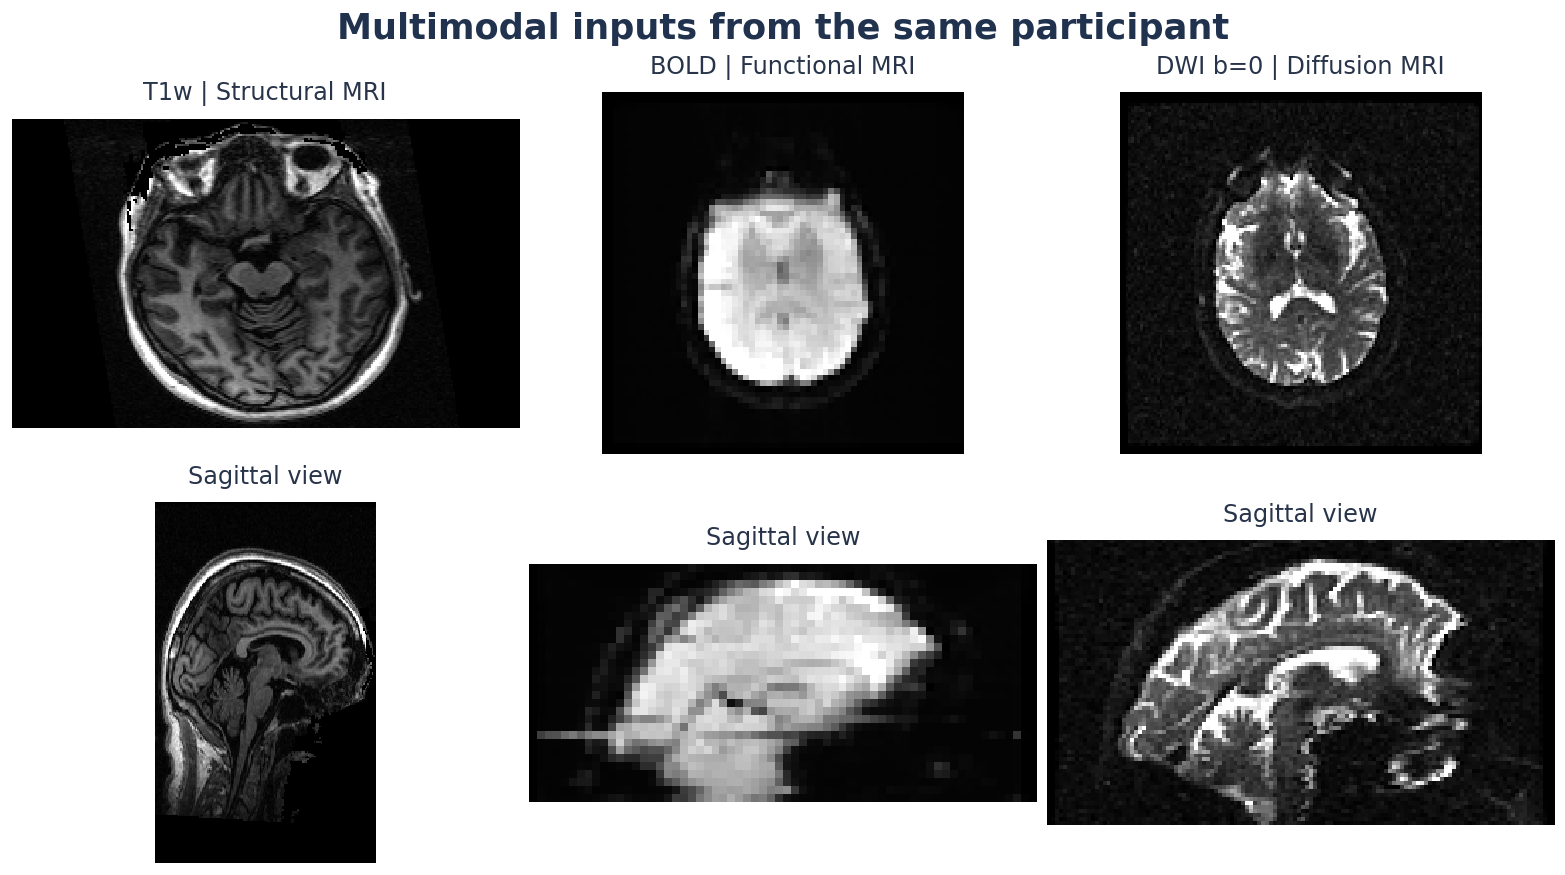

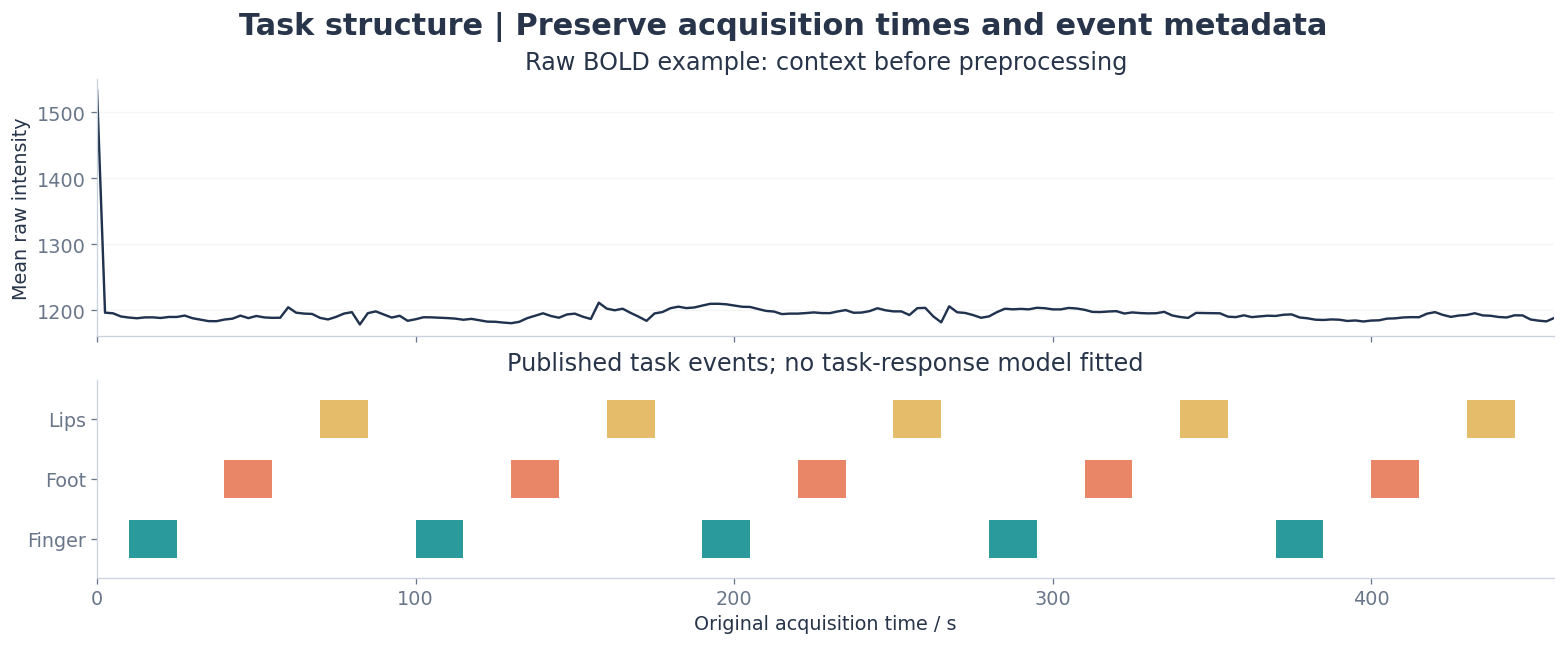

In [3]:
viz.modalities(t1, mean_bold, b0, FIGURES)
viz.task_context(events, t, x.mean(axis=1), FIGURES)
viz.note("Each modality is displayed in its own native geometry. These images are not cross-modal alignment results. "
         "The event timeline provides acquisition context; no task-response GLM is fitted.")

## 02 · What preprocessing changes

We separate operations that act on **physical geometry**, **physical time**, and **signal values**. Their effects are different, and so are their validation criteria.

| Layer | Core question | Demonstrated operations |
|:---|:---|:---|
| Spatial | Where is a voxel, and which location does it correspond to? | Reorientation, grid resampling, smoothing, rigid alignment |
| Temporal | When was a sample acquired, and which samples are valid? | Anti-aliased resampling, cropping, masked padding |
| Signal | Which model-defined variation is removed? | DCT drift and joint linear projection |
| Scale | Which baseline or amplitude information should be retained? | Centering, sample z-score, PSC, median/MAD |
| Quality | What changed, and what remains unknown? | Raw DVARS, original-signal tSNR, numerical checks |

The following figures illustrate individual operations. They are not combined into a validated production pipeline.

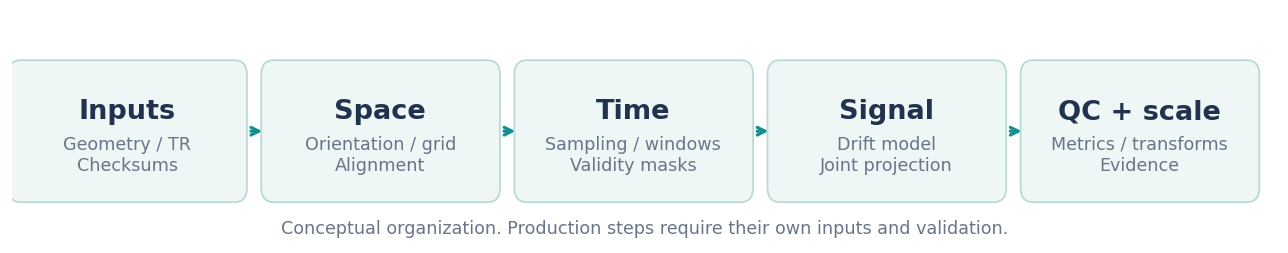

In [4]:
viz.workflow(FIGURES)

## 03 · Spatial orientation: preserve physical coordinates

**Problem.** NIfTI storage axes can differ between scans. This BOLD acquisition is stored approximately as **LAS**. We reorder and flip axes to obtain canonical **RAS** storage while updating the affine consistently.

$$\mathbf{r}_{\mathrm{world}} = \mathbf{A}\,[i,j,k,1]^\mathsf{T}.$$

If the array is reindexed by a transform $\mathbf{P}$, the new affine must map the new indices to the **same physical positions**. Axis reordering does not interpolate signal values and does not estimate anatomical registration.

**Validation:** reorient back to the original storage convention and compare every voxel value and the affine.

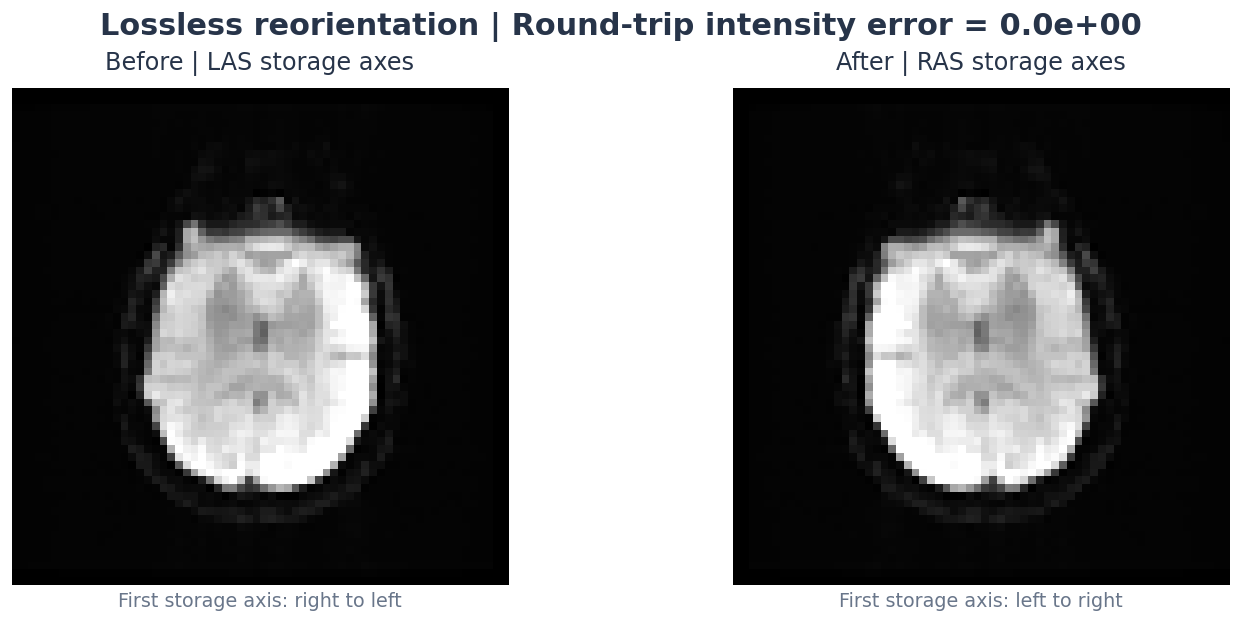

In [5]:
canonical_bold = canonical(mean_bold)
back_transform = nib.orientations.ornt_transform(
    nib.orientations.io_orientation(canonical_bold.affine),
    nib.orientations.io_orientation(mean_bold.affine))
roundtrip = canonical_bold.as_reoriented(back_transform)
orientation_error = np.max(np.abs(roundtrip.get_fdata() - mean_bold.get_fdata()))
assert orientation_error == 0
np.testing.assert_allclose(roundtrip.affine, mean_bold.affine)
viz.orientation(mean_bold, canonical_bold, orientation_error, FIGURES)
viz.note("The apparent left-right flip is a change of storage convention. Physical coordinates and intensities are preserved. "
         "The original acquisition obliquity is retained.", "result")

## 04 · Voxel spacing: resample onto an explicit target grid

**Problem.** Voxel spacing, field of view and axis orientation vary across acquisitions. Once spatial correspondence is known, interpolation evaluates the input image at target-grid locations.

$$I_{\mathrm{target}}(\mathbf{j}) = \mathcal{I}\!\left(I_{\mathrm{source}},\;\mathbf{A}_{\mathrm{source}}^{-1}\mathbf{A}_{\mathrm{target}}\mathbf{j}\right).$$

We use **linear interpolation** for this continuous mean-BOLD image. Nearest-neighbor interpolation is appropriate for discrete labels. The two reference grids below are axis-aligned and use the same input scan; producing them also removes the stored acquisition obliquity by interpolation.

**Interpretation:** changing an approximately 4 mm acquired grid to 3 mm increases the number of sample locations. It cannot recover spatial detail that was never acquired.

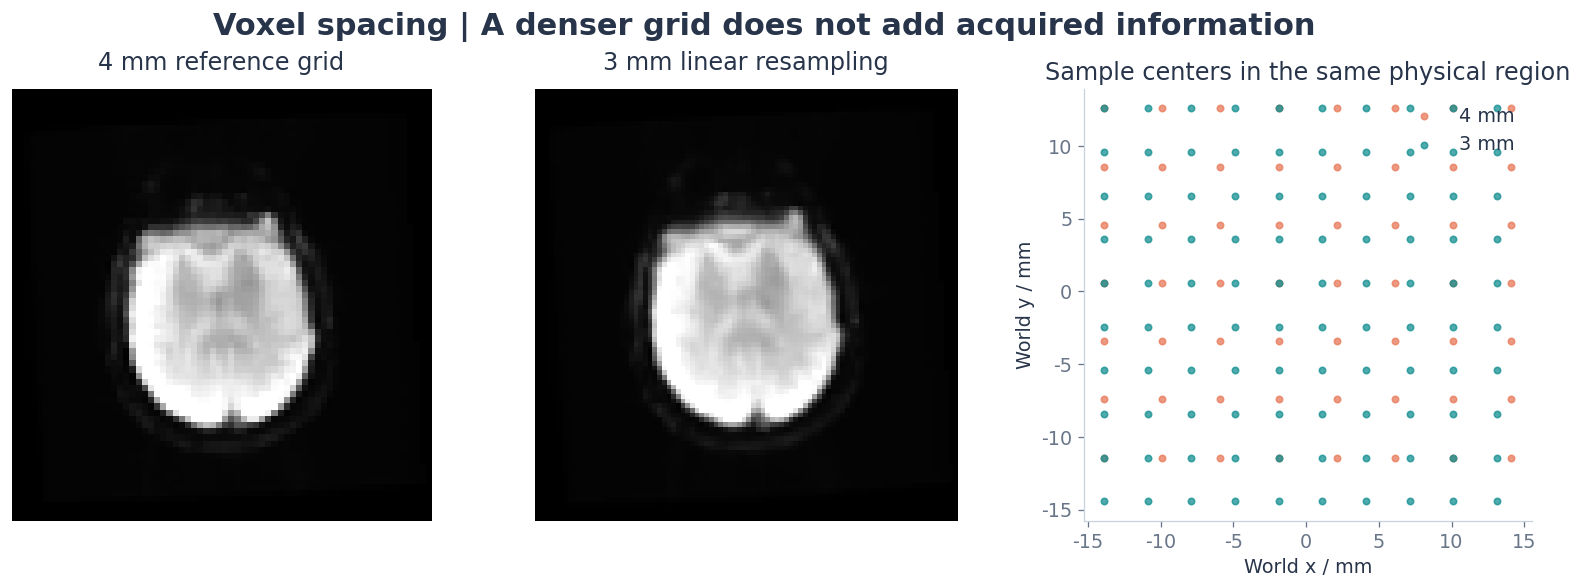

Quantity,4 mm reference,3 mm target
Grid shape,"(68, 70, 35)","(90, 92, 47)"
Grid spacing / mm,4 x 4 x 4,3 x 3 x 3
Acquired information,Same source scan,Same source scan


In [6]:
grid4 = resample_volume(mean_bold, spacing=(4, 4, 4), order=1)
grid3 = resample_volume(mean_bold, spacing=(3, 3, 3), order=1)
np.testing.assert_allclose(nib.affines.voxel_sizes(grid3.affine), [3, 3, 3])
back_on_grid4 = resample_from_to(grid3, grid4, order=1)
comparison_mask = grid4.get_fdata() > 0
roundtrip_mae = np.mean(np.abs(back_on_grid4.get_fdata()[comparison_mask]
                              - grid4.get_fdata()[comparison_mask]))
viz.spacing(grid4, grid3, roundtrip_mae, FIGURES)
viz.table(["Quantity", "4 mm reference", "3 mm target"], [
    ["Grid shape", str(grid4.shape), str(grid3.shape)],
    ["Grid spacing / mm", "4 x 4 x 4", "3 x 3 x 3"],
    ["Acquired information", "Same source scan", "Same source scan"]])
viz.note(f"The 3 mm to 4 mm round-trip mean absolute difference is {roundtrip_mae:.3f} intensity units "
         "over positive 4 mm reference voxels. This describes interpolation effects, not registration accuracy.")

## 05 · Spatial resolution: Gaussian smoothing

**Core algorithm.** Convolve the continuous image with a Gaussian kernel defined in **millimeters**:

$$I_{\mathrm{smooth}} = G_\sigma * I, \qquad
\sigma = \frac{\mathrm{FWHM}}{\sqrt{8\ln 2}}.$$

This example applies an additional **4 mm FWHM** kernel. Smoothing reduces local spatial variation and mixes neighboring signals. Voxel spacing and effective spatial resolution remain distinct properties.

**Choice condition:** retain the unsmoothed input when preserving fine spatial information is important. A smoothing kernel should follow the downstream objective rather than a universal preset.

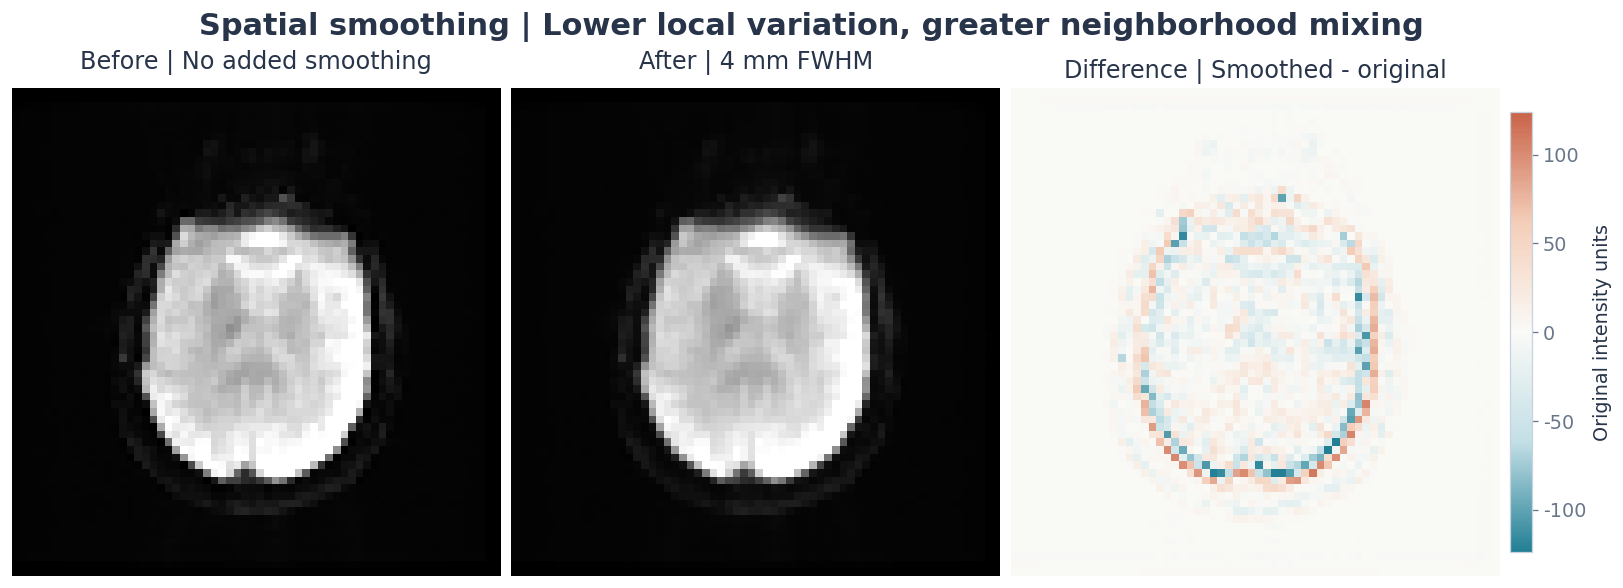

In [7]:
smoothed_bold = smooth_img(mean_bold, fwhm=4.0)
assert smoothed_bold.shape == mean_bold.shape
np.testing.assert_allclose(smoothed_bold.affine, mean_bold.affine)
smooth_mae = np.mean(np.abs(smoothed_bold.get_fdata()[mask] - mean_bold.get_fdata()[mask]))
viz.smoothing(mean_bold, smoothed_bold, mask, FIGURES)
viz.note(f"The before/after panels use the same grayscale range. Mean absolute signal change inside the estimated "
         f"EPI mask: {smooth_mae:.3f} intensity units. The difference map exposes where neighborhood averaging changes values.", "result")

## 06 · Cross-modal alignment: rigid mutual-information registration

**Problem.** A BOLD volume and a T1w scan have different contrast and geometry. A six-parameter rigid transform models three rotations and three translations.

$$\mathbf{r}_{\mathrm{moving}} = R(\boldsymbol{\theta})
(\mathbf{r}_{\mathrm{fixed}}-\mathbf{c}) + \mathbf{c}+\boldsymbol{\tau}, \qquad
\hat T = \arg\max_T \operatorname{MI}(I_{\mathrm{T1w}}, I_{\mathrm{BOLD}}\circ T).$$

The SimpleITK implementation minimizes **negative Mattes mutual information**. It uses a fixed seed, one thread, a coarse-to-fine pyramid and linear interpolation. SimpleITK transforms map **fixed physical coordinates to moving physical coordinates** for resampling.

This is a **low-resolution teaching example** without brain extraction, boundary-based registration, distortion correction or nonlinear normalization. The scan remains **REVIEW_REQUIRED**.

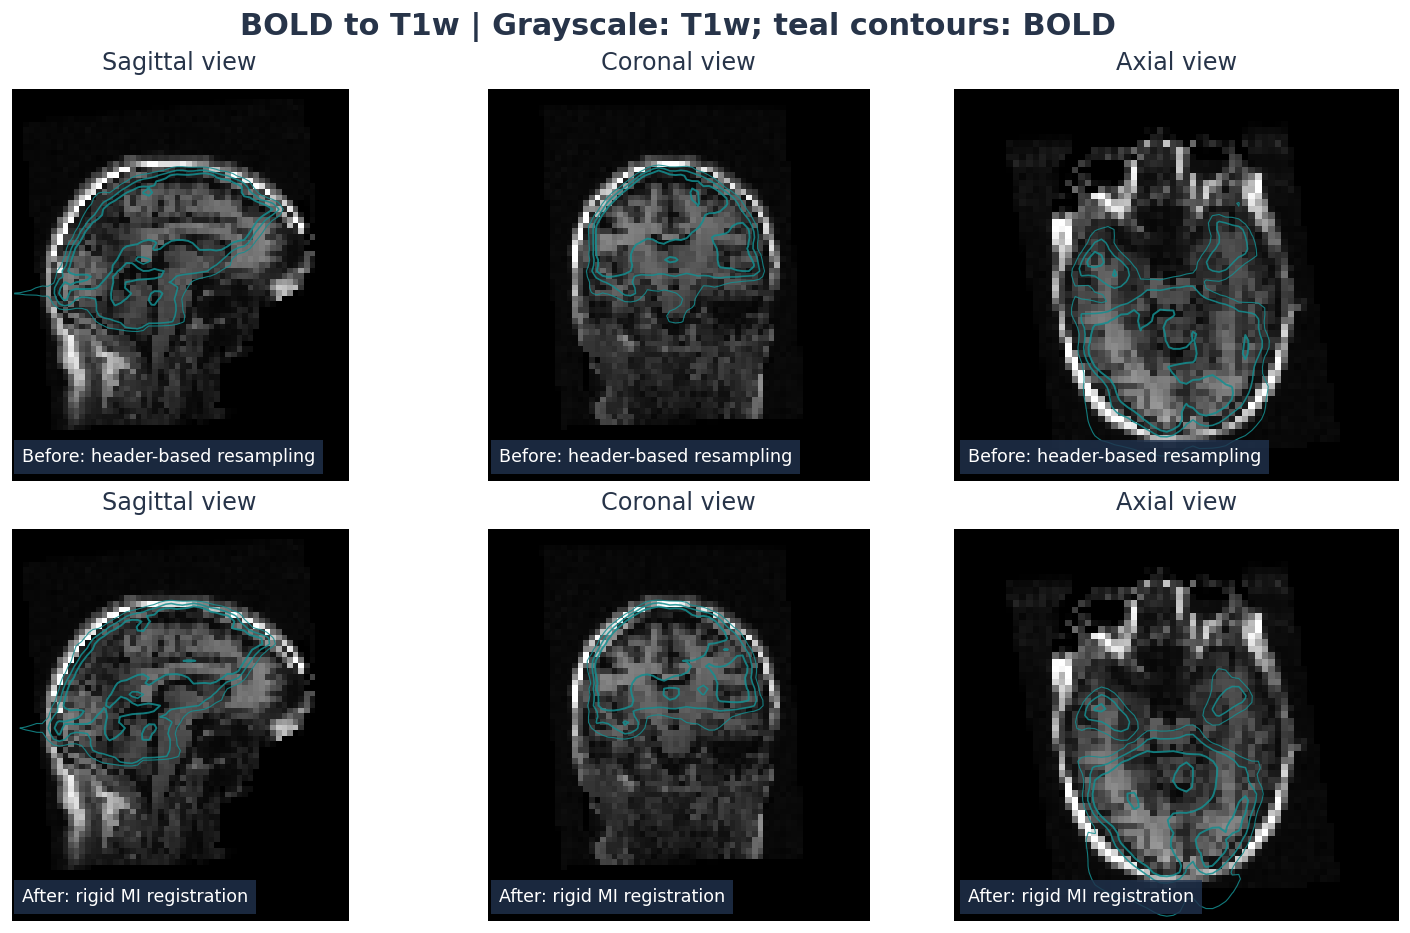

In [8]:
import SimpleITK as sitk
sitk.ProcessObject.SetGlobalDefaultNumberOfThreads(1)
fixed = resample_volume(t1, (4, 4, 4), order=1)
moving = resample_volume(mean_bold, (4, 4, 4), order=1)
WORK = REPORT / "work"
WORK.mkdir(exist_ok=True)
fixed_path, moving_path, registered_path = [WORK / n for n in
    ["t1w_4mm.nii.gz", "bold_4mm.nii.gz", "rigid_bold_to_t1w.nii.gz"]]
nib.save(fixed, fixed_path)
nib.save(moving, moving_path)
registration_metrics = rigid(fixed_path, moving_path, registered_path, metric="mi")
registered = nib.load(registered_path)
header_only = resample_from_to(moving, fixed, order=1)
viz.registration(fixed, header_only, registered, registration_metrics, FIGURES)
viz.cards([
    ("Optimization objective", f"{registration_metrics['objective_before']:.3f}", "Before: center-initialized transform"),
    ("Optimization objective", f"{registration_metrics['objective_after']:.3f}", "After: negative Mattes MI"),
    ("Transform model", "6 DOF", "Rigid; fixed-to-moving in ITK LPS"),
    ("Scan decision", "Review", "Objective change is not QC acceptance")])
viz.note("The top row uses header-based resampling only; the bottom row uses the fitted rigid transform. "
         "The displayed top-row transform differs from the center-initialized transform used for the 'before' optimization objective. "
         "Inspecting overlap is necessary, and this figure does not establish anatomical accuracy.")

## 07 · Temporal sampling: TR, Nyquist and anti-aliasing

**Core relationship.** $f_s=1/\mathrm{TR}$ and $f_{\mathrm{Nyquist}}=1/(2\mathrm{TR})$. For this scan, $\mathrm{TR}=2.5$ s, $f_s=0.4$ Hz, and the Nyquist frequency is $0.2$ Hz.

When moving to **5 s/sample**, we first apply a low-pass FIR filter and then downsample using a polyphase implementation:

$$y[m]=\sum_n x[n]h[mD-nU], \qquad \frac{U}{D}=\frac{\mathrm{TR}_{\mathrm{in}}}{\mathrm{TR}_{\mathrm{out}}}.$$

The output is restricted to the original time support. Resampling does not add independent observations. This example operates on a continuous original time axis; it does not bridge censored gaps. Slice-timing correction is a separate acquisition-specific operation and is not applied here.

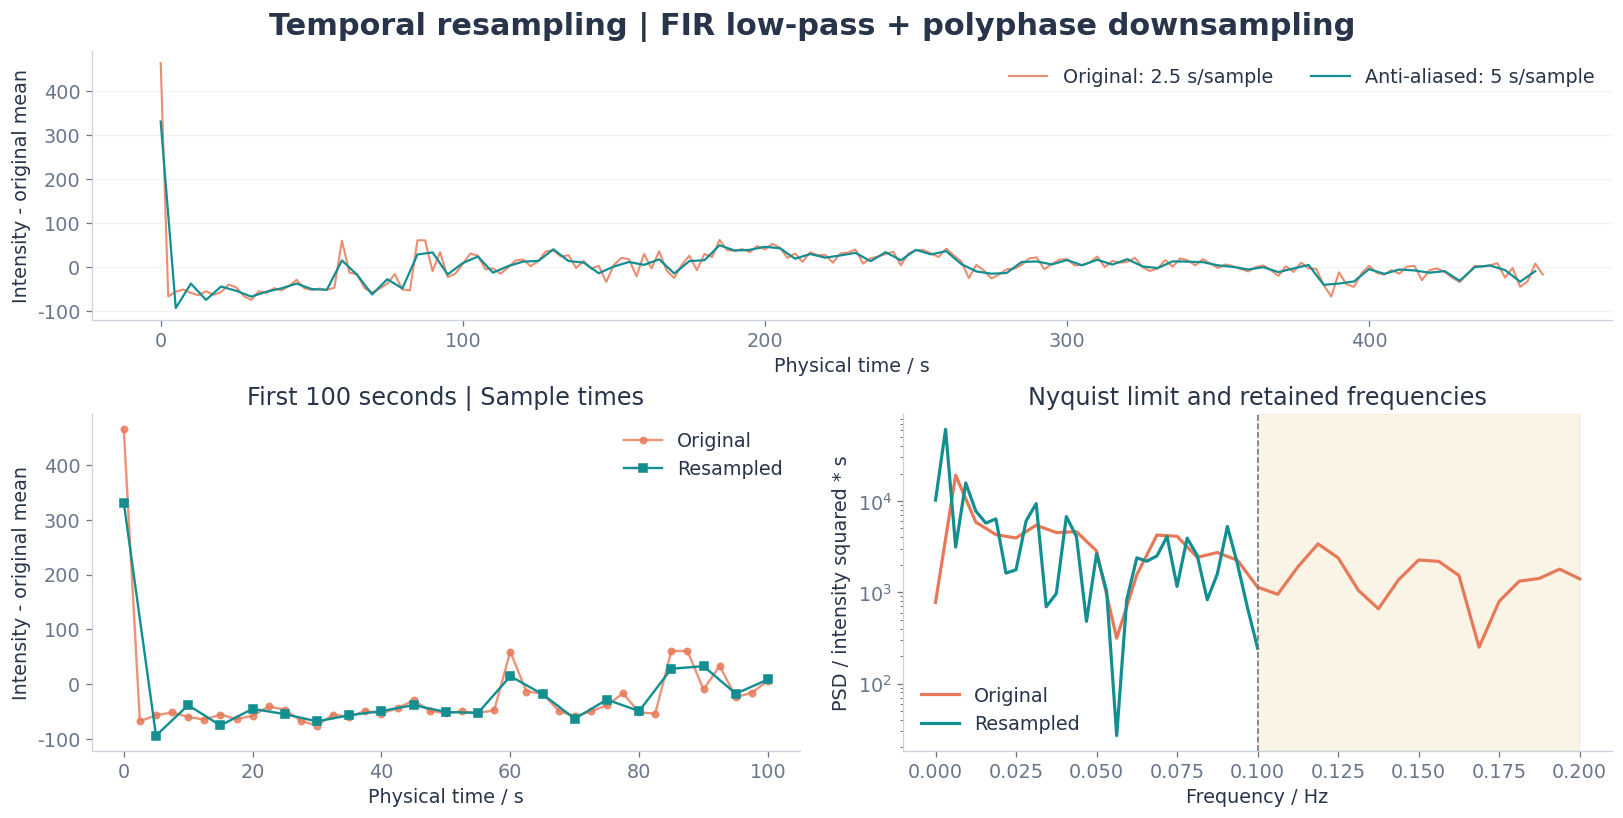

In [9]:
resampled, t_resampled = temporal_resample(x, tr_in=tr, tr_out=5.0)
assert t_resampled[-1] <= t[-1]
viz.temporal(x, resampled, t, t_resampled, tr, 5.0, FIGURES)
viz.cards([
    ("Original samples", str(len(x)), f"Nyquist: {0.5/tr:.2f} Hz"),
    ("Resampled samples", str(len(resampled)), "Nyquist: 0.10 Hz"),
    ("Final original onset", f"{t[-1]:.1f} s", "Acquired sample support"),
    ("Final output onset", f"{t_resampled[-1]:.1f} s", "No extrapolated tail")])
viz.note("The shaded spectrum region is above the new Nyquist limit. Its attenuation illustrates anti-aliasing, "
         "not evidence that the removed frequencies are non-neural.")

## 08 · Sequence length: cropping and masked padding

**Cropping** selects a real contiguous window, preserving its original indices. **Padding** creates model input positions and requires an explicit validity mask:

$$m_t=\begin{cases}1 & t<N_{\mathrm{real}}\0 & \text{padding}\end{cases}, \qquad
\bar x_{\mathrm{valid}} = \frac{\sum_t m_t x_t}{\sum_t m_t}.$$

The mask must be respected by normalization, attention and loss computation. Windows must not cross subjects, runs, dataset splits or censored gaps. The examples below do not censor real acquired samples.

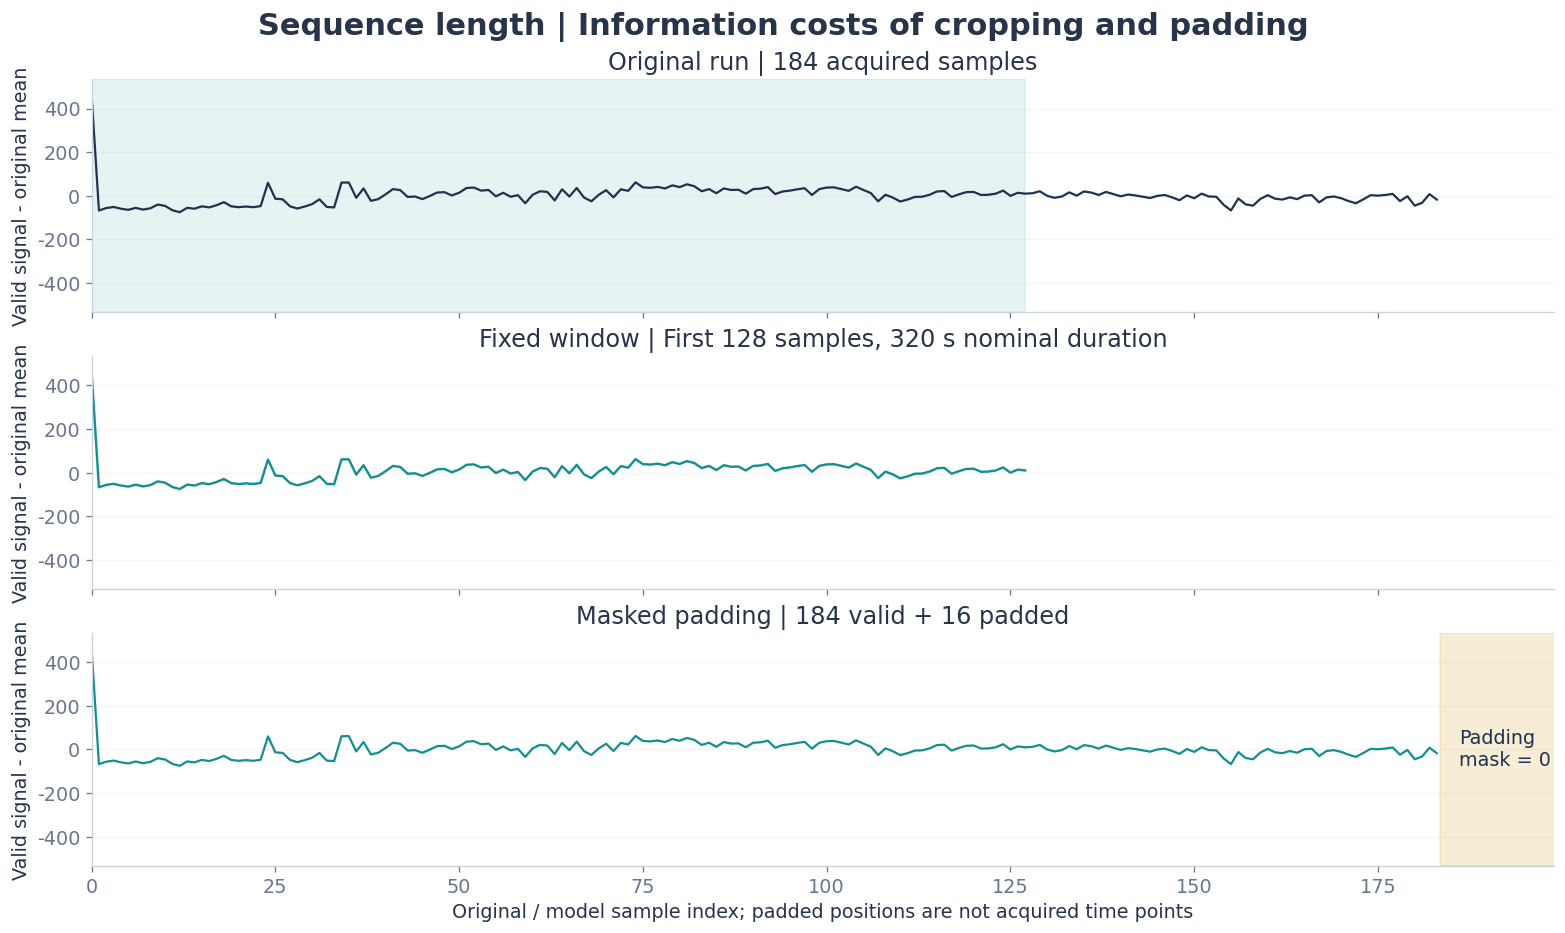

In [10]:
cropped, crop_valid = crop_or_pad(x, length=128)
padded, pad_valid = crop_or_pad(x, length=200)
assert crop_valid.all() and pad_valid.sum() == len(x)
np.testing.assert_array_equal(padded[pad_valid], x)
np.testing.assert_allclose(padded[pad_valid].mean(axis=0), x.mean(axis=0))
viz.windows(x, cropped, padded, pad_valid, tr, FIGURES)
viz.note("Cropping removes 56 acquired samples in this example. Padding adds 16 invalid model positions. "
         "Those positions are excluded from signal statistics and are never interpreted as acquired time points.", "result")

## 09 · Drift cleaning: DCT basis and joint projection

**Core algorithm.** Represent slow variation with discrete-cosine basis functions. The basis is generated on the complete original time axis:

$$d_k(t)=\cos\!\left[\frac{\pi k(t+1/2)}{N}\right], \qquad
K=\left\lfloor2N\,\mathrm{TR}\,f_{\mathrm{HP}}\right\rfloor.$$

If validated nuisance regressors are available, combine them with drift terms in **one design matrix** $C$. The joint least-squares residual is

$$Y_{\mathrm{clean}} = Y - C C^+Y.$$

With censoring, fit the same original-time design on retained rows and preserve the original indices. This avoids treating a compressed, gapped sequence as regularly sampled data. Here, **only drift and an intercept** are included because formal motion, tissue and physiology confounds are absent.

The **0.008 Hz** cutoff is an explicit teaching parameter. It has not been established as optimal for this task or for foundation-model pretraining.

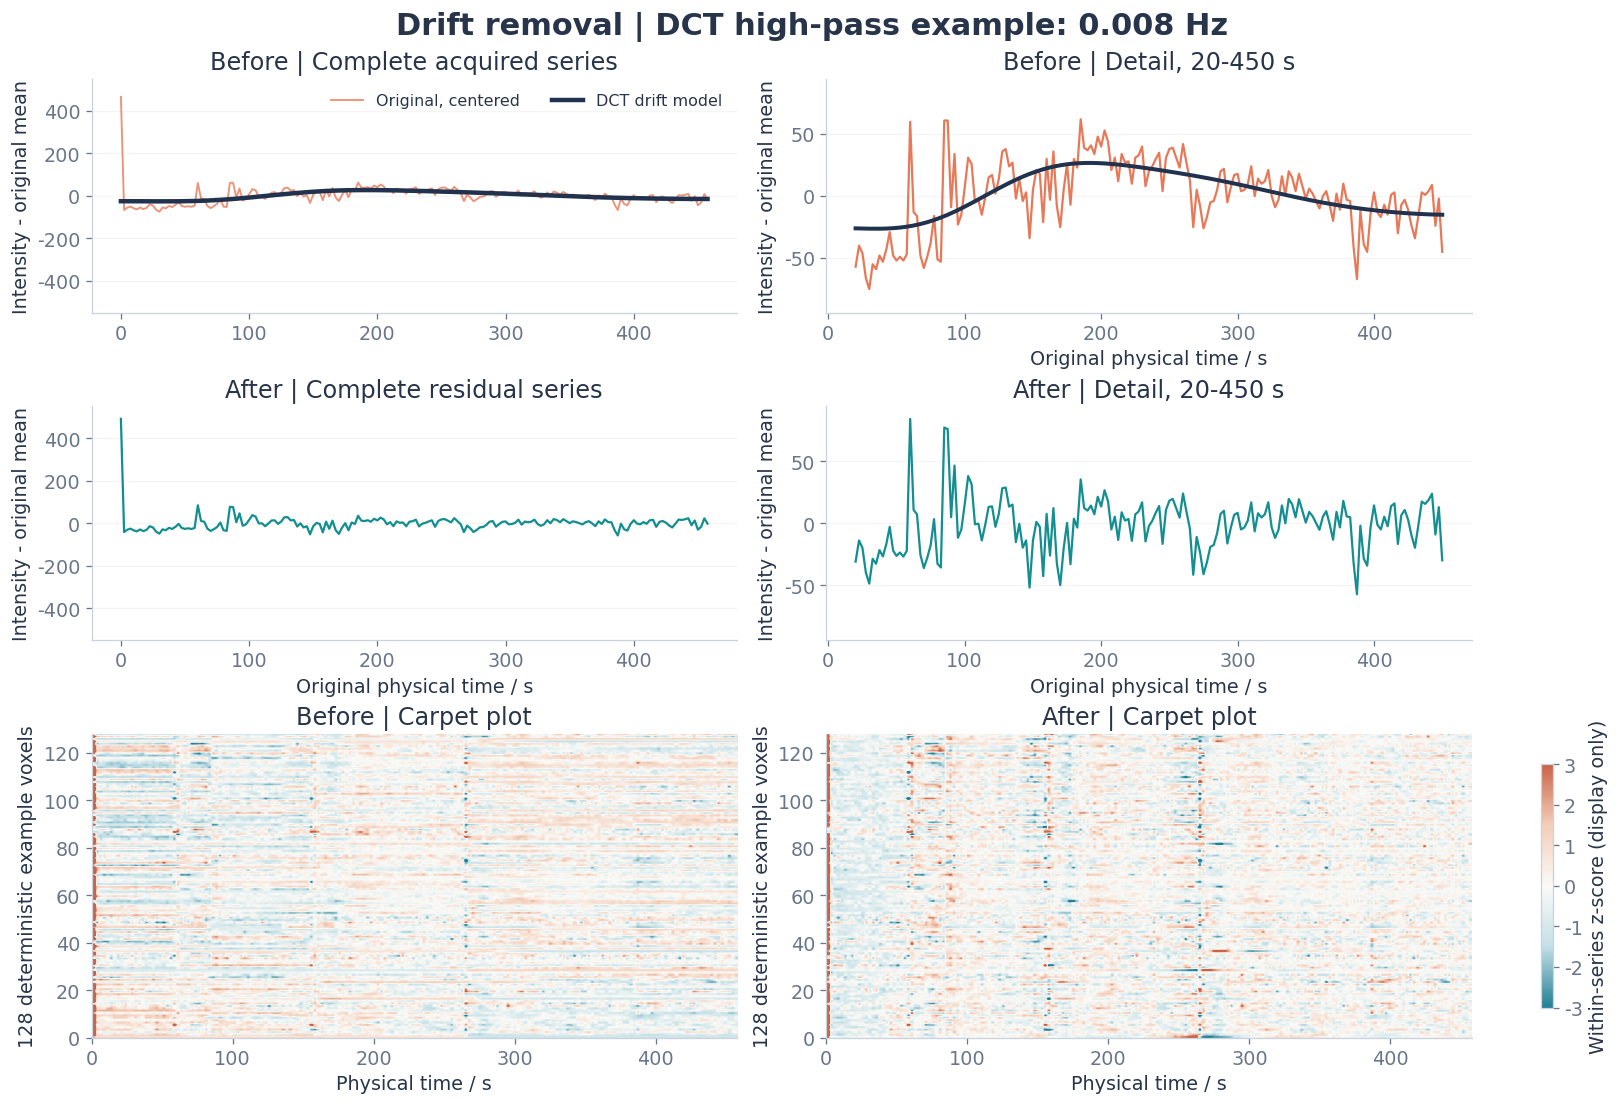

In [11]:
high_pass = 0.008
drift_design = drift_basis(n=len(x), tr=tr, high_pass=high_pass)
residual, regression_qc = regress(x, drift=drift_design)
projection_error = np.max(np.abs(drift_design.T @ residual))
assert projection_error < 1e-6
viz.drift(x, residual, t, high_pass, FIGURES)
viz.cards([
    ("High-pass example", f"{high_pass:.3f} Hz", "Specified before this visualization"),
    ("Design rank", str(regression_qc['rank']), "Intercept and DCT basis"),
    ("Algebraic residual DOF", str(regression_qc['algebraic_dof']), "Not a temporal-autocorrelation correction"),
    ("Orthogonality error", f"{projection_error:.1e}", "max |DCT.T @ residual|")])
viz.note("The upper trace uses a fixed example voxel; both carpet plots use the same 128 deterministic voxels. "
         "Carpet values are standardized separately for display. This reveals pattern changes but does not preserve absolute amplitude between panels. "
    "The detail panels show 20-450 seconds on a smaller shared vertical scale for readability only; all acquired samples remain in the fit. "
    "Drift removal is not complete artifact correction.")

## 10 · Signal scale: choose which information to retain

MRI signal intensity has an arbitrary baseline. Different transformations preserve different information, so they should not be treated as interchangeable denoising methods.

| Transformation | Core algorithm | Retained / changed information |
|:---|:---|:---|
| Centering | $x_t-\mu$ | Removes baseline; preserves temporal variance |
| Sample z-score | $(x_t-\mu)/s$, $s$ uses ddof = 1 | Removes per-voxel scale; unit sample variance |
| Percent signal change | $100(x_t-\mu)/|\mu|$ | Expresses amplitude relative to original baseline |
| Median / MAD | $(x_t-\operatorname{median}x)/(1.4826\operatorname{MAD})$ | Robust location and scale; different distribution |

**Implementation conditions:** compute statistics on valid samples; reject zero or degenerate denominators; retain the original baseline for PSC. Do not compute PSC by dividing zero-mean residuals by their residual mean. The density panels are descriptive displays of pooled values, not independent samples for inferential testing.

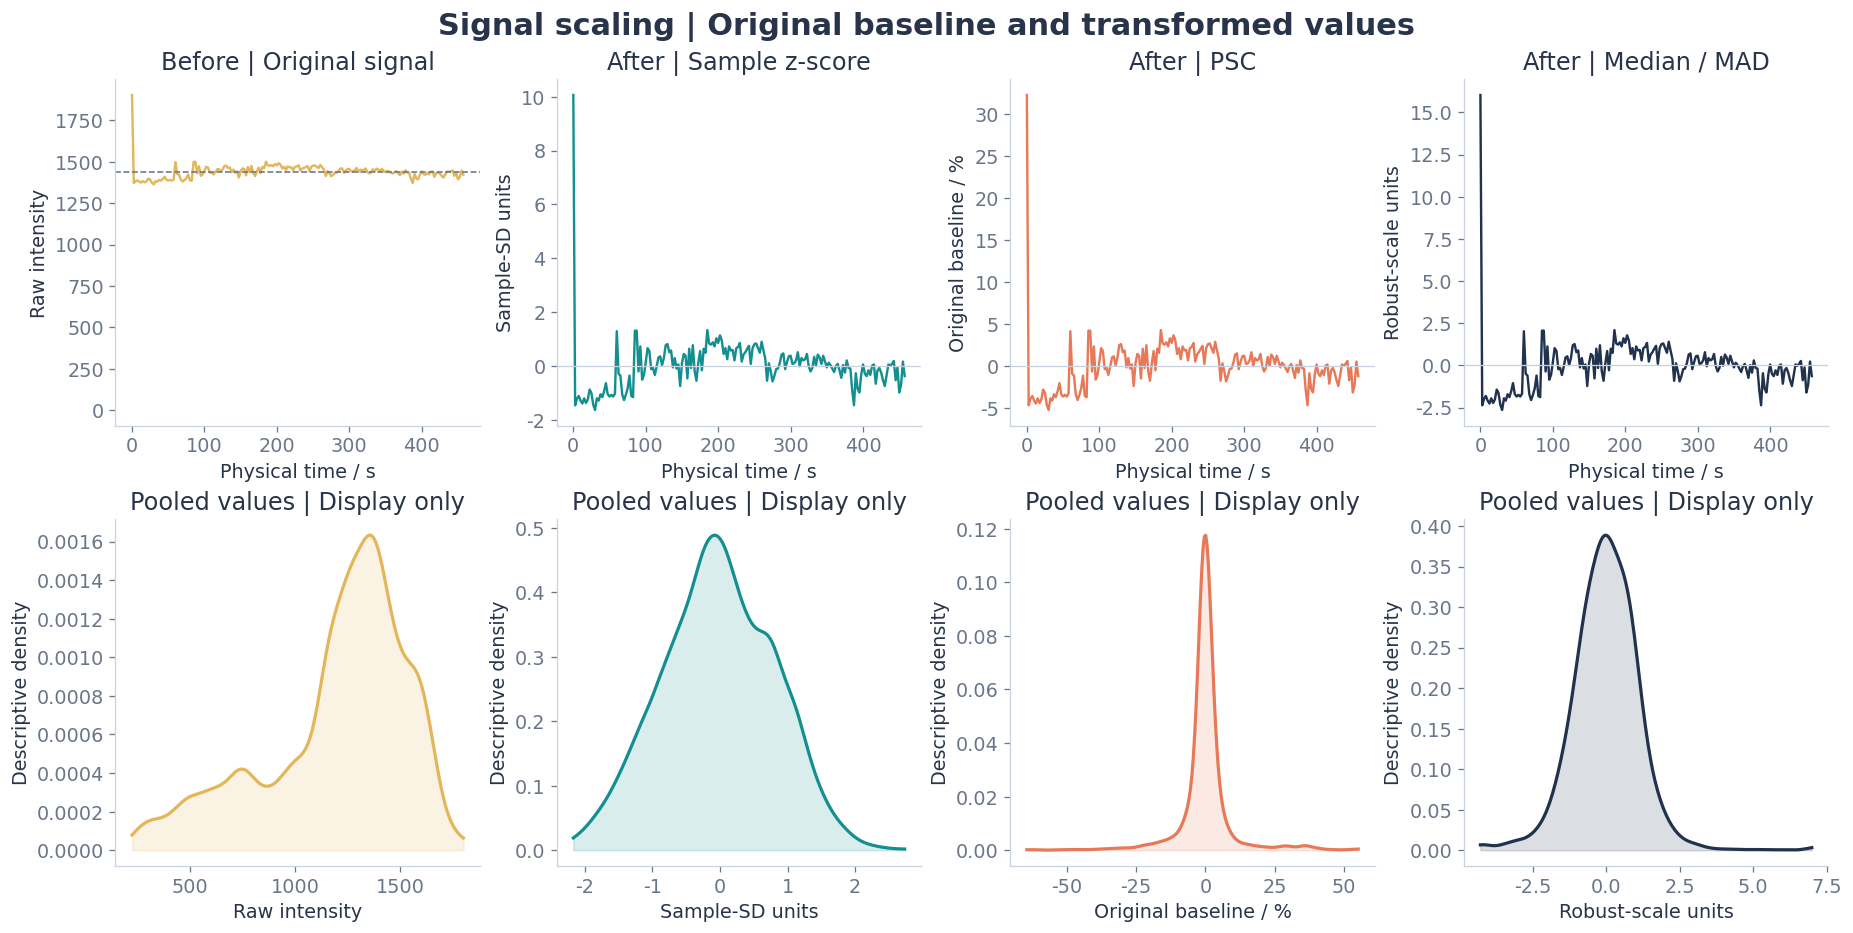

In [12]:
centered = scale(x, "center")
zscore = scale(x, "zscore")
psc = scale(x, "psc")
robust = scale(x, "robust")
np.testing.assert_allclose(centered.var(axis=0, ddof=1), x.var(axis=0, ddof=1))
np.testing.assert_allclose(zscore.mean(axis=0), 0, atol=1e-12)
np.testing.assert_allclose(zscore.std(axis=0, ddof=1), 1, atol=1e-12)
viz.scaling(x, zscore, psc, robust, t, FIGURES)
viz.note("Each column has its own explicitly labeled units. PSC retains relative amplitude; z-score removes each voxel's "
         "original amplitude scale. Robust scaling changes sensitivity to extreme values but does not remove their physical cause. "
         "Density panels display the central 99% of pooled values; all tail values remain in the calculations.", "result")

## 11 · Quality control: signal change and original-signal tSNR

**Raw DVARS** measures the root-mean-square signal difference between consecutive volumes over a specified voxel set:

$$\mathrm{DVARS}_t=\sqrt{\frac{1}{V}\sum_{v=1}^{V}(x_{t,v}-x_{t-1,v})^2}.$$

The first derivative is undefined. Raw DVARS depends on intensity units and differs from standardized DVARS. We compare raw input and DCT residuals using the **same 128 voxels and original intensity units**.

**tSNR** is computed from the original, uncentered data inside the full estimated EPI mask:

$$\mathrm{tSNR}_v=\frac{\mu_v}{s_v}.$$

The map is displayed in native canonical geometry. Original tSNR is not compared with tSNR after mean removal: the latter loses the original baseline interpretation. These diagnostics do not independently authorize scan inclusion.

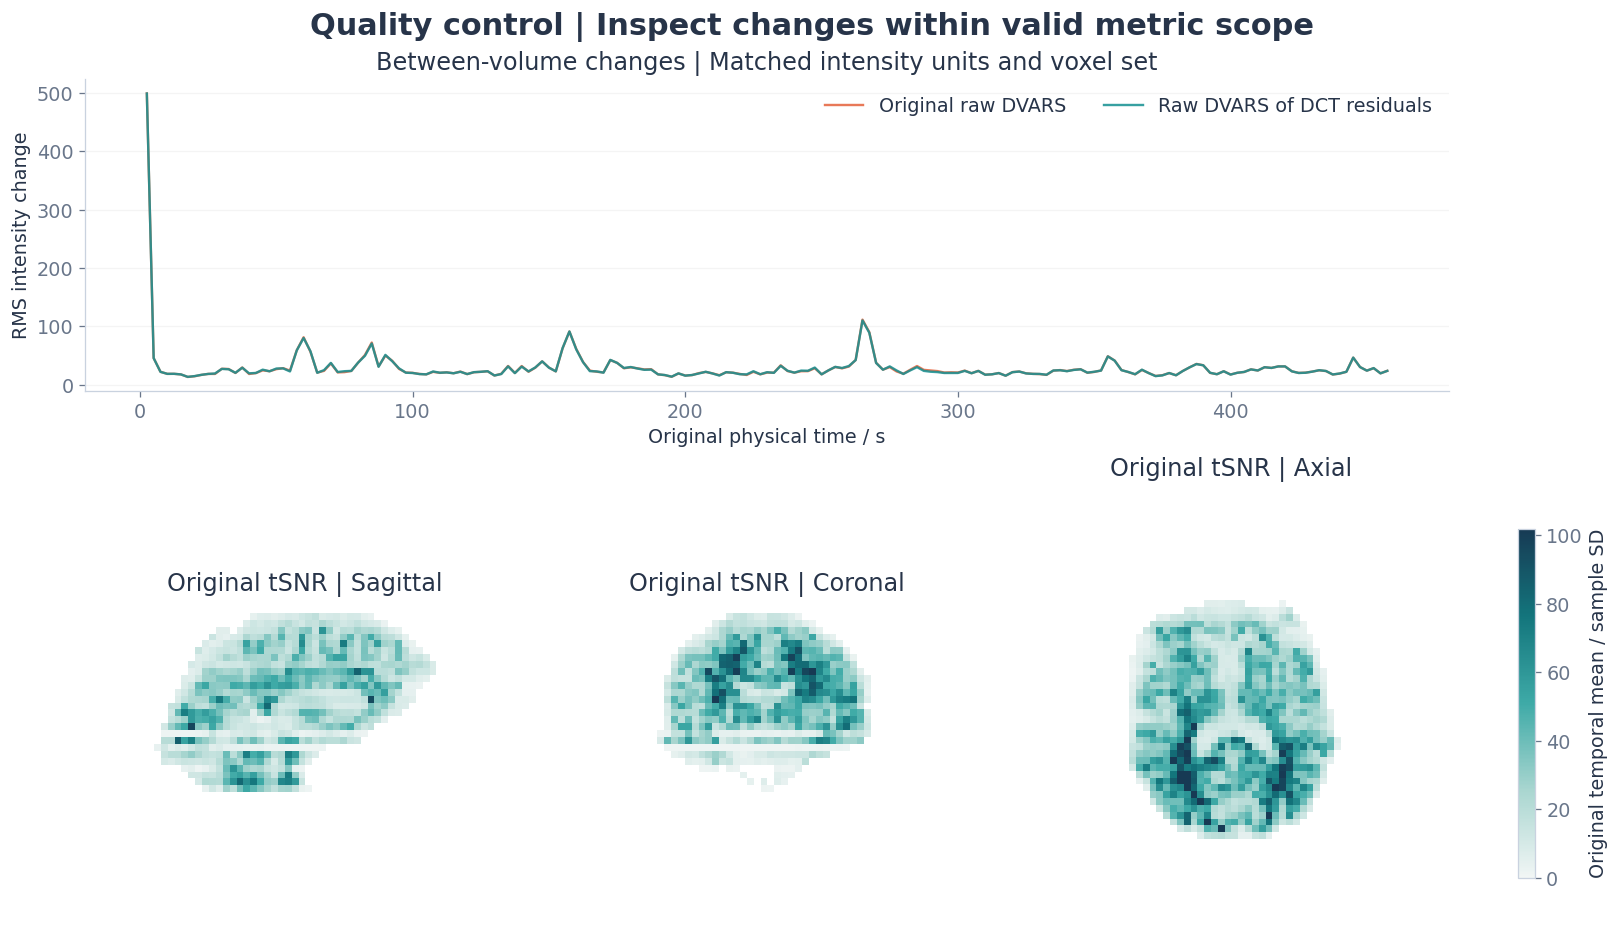

Metric,Measured scope,Result
Median raw DVARS,128 fixed example voxels,23.274 intensity units
Median residual DVARS,Same voxels and units,23.206 intensity units
Median original tSNR,"17,210 estimated EPI-mask voxels",28.212
Formal FD / standardized DVARS,Required upstream inputs absent,NOT_MEASURED
Anatomical brain coverage,Independent expected brain mask absent,NOT_MEASURED


In [13]:
raw_dv = dvars(x)
residual_dv = dvars(residual)
assert np.isnan(raw_dv[0]) and np.isnan(residual_dv[0])
full_signals = sample["data"][mask].T.astype(np.float64)
full_tsnr = tsnr(full_signals)
tsnr_map = np.full(mask.shape, np.nan, dtype=np.float64)
tsnr_map[mask] = full_tsnr
tsnr_image = canonical(nib.Nifti1Image(tsnr_map, mean_bold.affine, mean_bold.header))
mask_image = canonical(nib.Nifti1Image(mask.astype(np.uint8), mean_bold.affine, mean_bold.header))
viz.qc(raw_dv, residual_dv, t, tsnr_image.get_fdata(), mask_image.get_fdata().astype(bool), FIGURES)
viz.table(["Metric", "Measured scope", "Result"], [
    ["Median raw DVARS", "128 fixed example voxels", f"{np.nanmedian(raw_dv):.3f} intensity units"],
    ["Median residual DVARS", "Same voxels and units", f"{np.nanmedian(residual_dv):.3f} intensity units"],
    ["Median original tSNR", f"{mask.sum():,} estimated EPI-mask voxels", f"{np.nanmedian(full_tsnr):.3f}"],
    ["Formal FD / standardized DVARS", "Required upstream inputs absent", "NOT_MEASURED"],
    ["Anatomical brain coverage", "Independent expected brain mask absent", "NOT_MEASURED"]])
viz.note("No exclusion threshold was fitted from these results. The estimated EPI mask is not an independent anatomical "
         "coverage reference. A smaller DVARS value or a larger tSNR value alone does not establish neural signal preservation.")

## 12 · Verification and presentation takeaways

We check numerical invariants and independently compare scale transformations with the installed Nilearn implementation on both real runs. The original reference library also includes anti-aliasing, world-coordinate preservation, projection orthogonality and scientific-input failure checks.

The results below establish that the demonstrated implementations behave as specified. **Two runs from one participant cannot establish a universally best preprocessing method, cross-site robustness or a downstream pretraining improvement.**

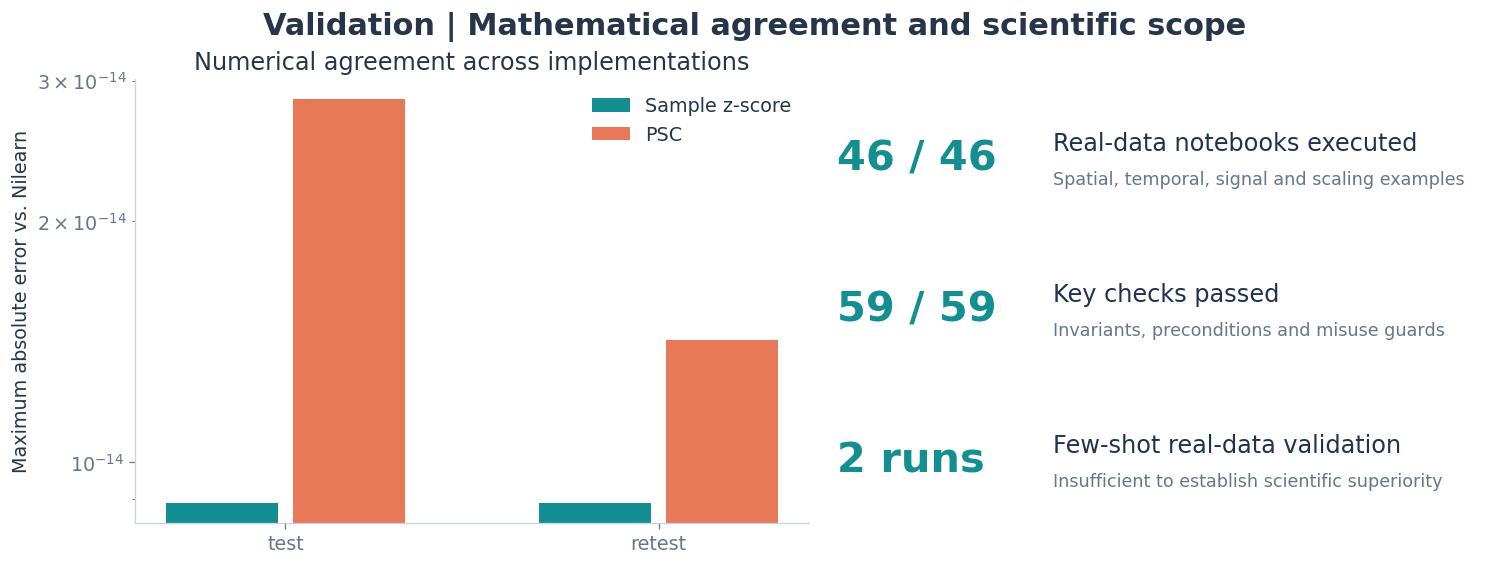

Method,What we demonstrated,What the figure does not establish
Reorientation,Lossless array/affine transformation,Anatomical registration
Grid resampling,Explicit spacing and interpolation,Improved acquired spatial resolution
Smoothing,Gaussian convolution and local differences,A universally appropriate smoothing width
Rigid registration,MI optimization and three-plane overlays,Production-quality acceptance or nonlinear normalization
Temporal resampling,Anti-aliasing and physical timing,Recovery of information above the source Nyquist limit
Cropping / padding,Real windows and explicit validity masks,New acquired observations
DCT regression,Specified slow-variation model and residuals,Complete motion / physiological artifact correction
Scaling,Baseline/variance transformations with numerical agreement,A scientifically optimal model input scale


3669

In [14]:
errors = {}
for session_name, data in [("test", sample), ("retest", retest)]:
    signals = data["signals"]
    reference_z = nilearn_signal.clean(signals, detrend=False,
        standardize="zscore_sample", filter=False)
    reference_psc = nilearn_signal.clean(signals, detrend=False,
        standardize="psc", filter=False)
    errors[session_name] = {
        "zscore": float(np.max(np.abs(scale(signals, "zscore") - reference_z))),
        "psc": float(np.max(np.abs(scale(signals, "psc") - reference_psc)))}
    assert errors[session_name]["zscore"] < 1e-10
    assert errors[session_name]["psc"] < 1e-10
assert summary["executed"] == 46 and summary["failed"] == 0
assert summary["tests"]["count"] == 59
viz.reproducibility(errors, FIGURES)
viz.table(["Method", "What we demonstrated", "What the figure does not establish"], [
    ["Reorientation", "Lossless array/affine transformation", "Anatomical registration"],
    ["Grid resampling", "Explicit spacing and interpolation", "Improved acquired spatial resolution"],
    ["Smoothing", "Gaussian convolution and local differences", "A universally appropriate smoothing width"],
    ["Rigid registration", "MI optimization and three-plane overlays", "Production-quality acceptance or nonlinear normalization"],
    ["Temporal resampling", "Anti-aliasing and physical timing", "Recovery of information above the source Nyquist limit"],
    ["Cropping / padding", "Real windows and explicit validity masks", "New acquired observations"],
    ["DCT regression", "Specified slow-variation model and residuals", "Complete motion / physiological artifact correction"],
    ["Scaling", "Baseline/variance transformations with numerical agreement", "A scientifically optimal model input scale"]])
viz.note("Production motion correction, formal FD, standardized DVARS, non-steady-state labeling, anatomical coverage, "
         "susceptibility correction, tissue-based aCompCor, real RETROICOR and ICA-AROMA/tedana remain unrun or unmeasured. "
         "The notebook does not label missing quantities as zero or convert optimizer convergence into scientific success.")

report_metrics = {
    "dataset": "ds000114", "participant": "sub-01", "sessions": ["test", "retest"],
    "input_hashes_verified": len(manifest), "tr_seconds": tr, "n_volumes": len(x),
    "orientation_roundtrip_max_error": float(orientation_error),
    "resampling_roundtrip_mae": float(roundtrip_mae), "smoothing_mask_mae": float(smooth_mae),
    "registration": registration_metrics, "registration_acceptance": "REVIEW_REQUIRED",
    "resampled_n_volumes": len(resampled), "resampled_last_onset_seconds": float(t_resampled[-1]),
    "dct": regression_qc, "dct_orthogonality_error": float(projection_error),
    "nilearn_agreement": errors, "raw_tsnr_median_full_epi_mask": float(np.nanmedian(full_tsnr)),
    "original_epi_mask_voxels": int(mask.sum()),
    "raw_dvars_median_example_voxels": float(np.nanmedian(raw_dv)),
    "residual_dvars_median_example_voxels": float(np.nanmedian(residual_dv)),
    "scientific_status": "Real-data teaching demonstrations; production-pipeline comparison incomplete"}
(REPORT / "report_metrics.json").write_text(json.dumps(report_metrics, indent=2, allow_nan=False))

## References and reproducibility

- **Dataset:** [OpenNeuro ds000114, version 1.0.2](https://openneuro.org/datasets/ds000114/versions/1.0.2), CC0. Exact Git tree, S3 object versions and hashes are recorded in `provenance/data_manifest.json`.
- **Geometry:** [NiBabel coordinate systems](https://nipy.org/nibabel/coordinate_systems.html) and the repository's frozen source references.
- **Registration:** [SimpleITK registration overview](https://simpleitk.readthedocs.io/en/master/registrationOverview.html). The report uses the installed SimpleITK version recorded in `provenance/installed_versions.json`.
- **Temporal resampling:** [SciPy resample_poly](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.resample_poly.html).
- **Joint preprocessing:** Lindquist et al. (2019), *Modular preprocessing pipelines can reintroduce artifacts into fMRI data*, [DOI: 10.1002/hbm.24528](https://doi.org/10.1002/hbm.24528).
- **Confound strategy tradeoffs:** Ciric et al. (2017), [DOI: 10.1016/j.neuroimage.2017.03.020](https://doi.org/10.1016/j.neuroimage.2017.03.020); Parkes et al. (2018), [DOI: 10.1016/j.neuroimage.2017.12.073](https://doi.org/10.1016/j.neuroimage.2017.12.073).
- **Scale APIs:** [Nilearn signal.clean](https://nilearn.github.io/stable/modules/generated/nilearn.signal.clean.html).

**Repository implementation:** `fmri_reference/core.py`, `registration.py`, and `reports/presentation/report_visuals.py`.  
**Saved numerical results:** `reports/presentation/report_metrics.json`.  
**Environment:** Python 3.12 and the repository's dependency locks.  
**Source scope:** the report reuses the existing literature/code audit; it is not a new systematic review.

To rerun, open this notebook inside the reference repository using its configured environment. Input data must pass the frozen manifest checks. The first cell also supports `FMRI_REFERENCE_ROOT` when the notebook is opened from another directory.